## Pre-Processing

In [1]:
import requests
import re

book_url = "https://www.gutenberg.org/cache/epub/5200/pg5200.txt"

response = requests.get(book_url)
response.raise_for_status()

raw_text = response.text

print("Raw character count:", len(raw_text))
print(raw_text[:1000])

Raw character count: 140488
The Project Gutenberg eBook of Metamorphosis
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

*** This is a COPYRIGHTED Project Gutenberg eBook. Details Below. ***
***     Please follow the copyright guidelines in this file.      ***


Title: Metamorphosis

Author: Franz Kafka

Translator: David Wyllie


        
Release date: August 17, 2005 [eBook #5200]
                Most recently updated: June 9, 2026

Language: English

Other information and formats: www.gutenberg.org/ebooks/5200


*** START OF THE PROJECT GUTENBERG EBOOK METAMORPHOSIS ***




I


O


In [2]:
start_match = re.search(
    r"\*\*\* START OF THE PROJECT GUTENBERG EBOOK METAMORPHOSIS \*\*\*",
    raw_text
)

end_match = re.search(
    r"\*\*\* END OF THE PROJECT GUTENBERG EBOOK METAMORPHOSIS \*\*\*",
    raw_text
)

if start_match and end_match:
    book_text = raw_text[start_match.end():end_match.start()]
else:
    book_text = raw_text

book_text = book_text.strip()

print(book_text[:1500])

I


One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections.
The bedding was hardly able to cover it and seemed ready to slide off
any moment. His many legs, pitifully thin compared with the size of the
rest of him, waved about helplessly as he looked.

“What’s happened to me?” he thought. It wasn’t a dream. His room, a
proper human room although a little too small, lay peacefully between
its four familiar walls. A collection of textile samples lay spread out
on the table—Samsa was a travelling salesman—and above it there hung a
picture that he had recently cut out of an illustrated magazine and
housed in a nice, gilded frame. It showed a lady fitted out with a fur
hat and fur boa who sat upright, raising a heavy fur muff that covered
the whole of her lower arm towards 

In [3]:
book_text = book_text.replace("\r\n", "\n")
book_text = book_text.replace("\r", "\n")

book_text = re.sub(r"\n{3,}", "\n\n", book_text)

print(book_text[:1500])

I

One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections.
The bedding was hardly able to cover it and seemed ready to slide off
any moment. His many legs, pitifully thin compared with the size of the
rest of him, waved about helplessly as he looked.

“What’s happened to me?” he thought. It wasn’t a dream. His room, a
proper human room although a little too small, lay peacefully between
its four familiar walls. A collection of textile samples lay spread out
on the table—Samsa was a travelling salesman—and above it there hung a
picture that he had recently cut out of an illustrated magazine and
housed in a nice, gilded frame. It showed a lady fitted out with a fur
hat and fur boa who sat upright, raising a heavy fur muff that covered
the whole of her lower arm towards t

In [4]:
words = book_text.split()
paragraphs = [p for p in book_text.split("\n\n") if p.strip()]

print("Clean character count:", len(book_text))
print("Word count:", len(words))
print("Paragraph count:", len(paragraphs))

print("\nFirst paragraph:")
print(paragraphs[0])

print("\nLast paragraph:")
print(paragraphs[-1])

Clean character count: 118406
Word count: 21935
Paragraph count: 100

First paragraph:
I

Last paragraph:
After that, the three of them left the flat together, which was
something they had not done for months, and took the tram out to the
open country outside the town. They had the tram, filled with warm
sunshine, all to themselves. Leant back comfortably on their seats,
they discussed their prospects and found that on closer examination
they were not at all bad—until then they had never asked each other
about their work but all three had jobs which were very good and held
particularly good promise for the future. The greatest improvement for
the time being, of course, would be achieved quite easily by moving
house; what they needed now was a flat that was smaller and cheaper
than the current one which had been chosen by Gregor, one that was in a
better location and, most of all, more practical. All the time, Grete
was becoming livelier. With all the worry they had been having of late


In [5]:
parts = re.split(r"\n\s*(?:I|II|III)\s*\n", book_text)

parts = [p.strip() for p in parts if p.strip()]

print("Number of parts:", len(parts))

for i, part in enumerate(parts, start=1):
    print(f"Part {i}: {len(part.split())} words")

Number of parts: 3
Part 1: 7083 words
Part 2: 7464 words
Part 3: 7386 words


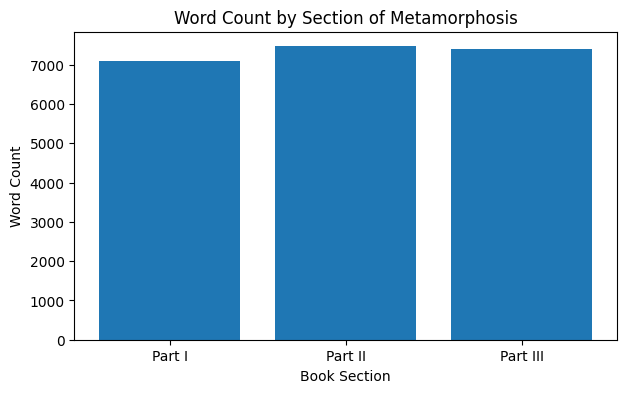

In [6]:
import matplotlib.pyplot as plt

part_word_counts = [len(part.split()) for part in parts]

plt.figure(figsize=(7, 4))
plt.bar(
    ["Part I", "Part II", "Part III"],
    part_word_counts
)

plt.xlabel("Book Section")
plt.ylabel("Word Count")
plt.title("Word Count by Section of Metamorphosis")
plt.show()

### Tokenizer


In [7]:
!pip install -q transformers sentencepiece

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

if torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

print("Device:", DEVICE)

Device: cuda


In [8]:
sum_name = "sshleifer/distilbart-cnn-12-6"
sum_tok = AutoTokenizer.from_pretrained(sum_name)

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

In [9]:
MAX_CHUNK_TOKENS = 900

def count_tokens(text):
    return len(
        sum_tok.encode(
            text,
            add_special_tokens=False
        )
    )

chunks = []
current_paragraphs = []
current_token_count = 0

for paragraph in paragraphs:
    paragraph = paragraph.strip()

    if not paragraph:
        continue

    paragraph_ids = sum_tok.encode(
        paragraph,
        add_special_tokens=False
    )

    # If one paragraph alone is longer than 900 tokens,
    # split that paragraph into smaller pieces.
    if len(paragraph_ids) > MAX_CHUNK_TOKENS:

        if current_paragraphs:
            chunks.append("\n\n".join(current_paragraphs))
            current_paragraphs = []
            current_token_count = 0

        for i in range(0, len(paragraph_ids), MAX_CHUNK_TOKENS):
            piece_ids = paragraph_ids[i:i + MAX_CHUNK_TOKENS]
            piece = sum_tok.decode(
                piece_ids,
                skip_special_tokens=True
            )
            chunks.append(piece)

        continue

    # Add paragraph if it still fits in current chunk.
    if current_token_count + len(paragraph_ids) <= MAX_CHUNK_TOKENS:
        current_paragraphs.append(paragraph)
        current_token_count += len(paragraph_ids)

    # Otherwise finish current chunk and start another.
    else:
        chunks.append("\n\n".join(current_paragraphs))

        current_paragraphs = [paragraph]
        current_token_count = len(paragraph_ids)

# Add final unfinished chunk
if current_paragraphs:
    chunks.append("\n\n".join(current_paragraphs))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1063 > 1024). Running this sequence through the model will result in indexing errors


In [10]:
chunk_token_counts = [count_tokens(chunk) for chunk in chunks]

print("Number of chunks:", len(chunks))
print("Smallest chunk:", min(chunk_token_counts), "tokens")
print("Largest chunk:", max(chunk_token_counts), "tokens")
print(
    "Average chunk size:",
    round(sum(chunk_token_counts) / len(chunk_token_counts), 1),
    "tokens"
)

print("\nFirst chunk token count:", chunk_token_counts[0])
print("\nFirst 500 characters of first chunk:")
print(chunks[0][:500])

Number of chunks: 42
Smallest chunk: 66 tokens
Largest chunk: 900 tokens
Average chunk size: 691.5 tokens

First chunk token count: 640

First 500 characters of first chunk:
I

One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections.
The bedding was hardly able to cover it and seemed ready to slide off
any moment. His many legs, pitifully thin compared with the size of the
rest of him, waved about helplessly as he looked.

“What’s happened to me?” he


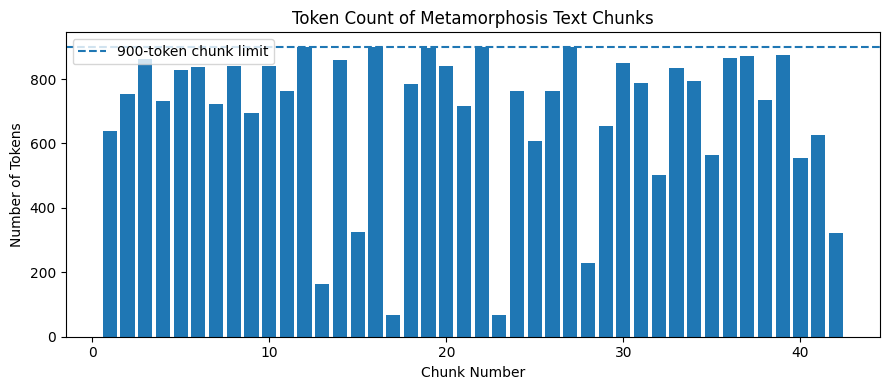

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.bar(
    range(1, len(chunk_token_counts) + 1),
    chunk_token_counts
)

plt.axhline(
    y=900,
    linestyle="--",
    label="900-token chunk limit"
)

plt.xlabel("Chunk Number")
plt.ylabel("Number of Tokens")
plt.title("Token Count of Metamorphosis Text Chunks")
plt.legend()
plt.tight_layout()
plt.show()

## Text Summarization with DistilBART


In [12]:
sum_model = AutoModelForSeq2SeqLM.from_pretrained(sum_name)
sum_model = sum_model.to(DEVICE)

print("Summarization model loaded on:", DEVICE)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

Summarization model loaded on: cuda


In [13]:
sample_text = chunks[0]

inputs = sum_tok(
    sample_text,
    return_tensors="pt",
    max_length=1024,
    truncation=True
)

inputs = {
    key: value.to(DEVICE)
    for key, value in inputs.items()
}

In [14]:
summary_ids = sum_model.generate(
    **inputs,
    num_beams=4,
    min_length=50,
    max_length=140,
    no_repeat_ngram_size=3
)

summary = sum_tok.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("ORIGINAL:")
print(sample_text[:2000])

print("\nSUMMARY:")
print(summary)

ORIGINAL:
I

One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections.
The bedding was hardly able to cover it and seemed ready to slide off
any moment. His many legs, pitifully thin compared with the size of the
rest of him, waved about helplessly as he looked.

“What’s happened to me?” he thought. It wasn’t a dream. His room, a
proper human room although a little too small, lay peacefully between
its four familiar walls. A collection of textile samples lay spread out
on the table—Samsa was a travelling salesman—and above it there hung a
picture that he had recently cut out of an illustrated magazine and
housed in a nice, gilded frame. It showed a lady fitted out with a fur
hat and fur boa who sat upright, raising a heavy fur muff that covered
the whole of her lower arm

In [15]:
summary_ids_2 = sum_model.generate(
    **inputs,
    num_beams=4,
    min_length=35,
    max_length=90,
    no_repeat_ngram_size=3
)

summary_2 = sum_tok.decode(
    summary_ids_2[0],
    skip_special_tokens=True
)

print("SUMMARY - EXPERIMENT 2:")
print(summary_2)

SUMMARY - EXPERIMENT 2:
 Gregor Samsa woke from troubled dreams to find himself transformed in his bed into a horrible vermin . His many legs, pitifully thin compared with the size of the rest of him, waved about helplessly as he looked . He felt a slight itch up on his belly; found where the itch was, and saw that it was covered with white spots .


In [16]:
summary_ids_3 = sum_model.generate(
    **inputs,
    num_beams=2,
    min_length=35,
    max_length=90,
    no_repeat_ngram_size=3
)

summary_3 = sum_tok.decode(
    summary_ids_3[0],
    skip_special_tokens=True
)

print("SUMMARY - EXPERIMENT 3:")
print(summary_3)

SUMMARY - EXPERIMENT 3:
 Gregor Samsa was a travelling salesman who was transformed in his bed into a horrible vermin . Samsa woke from troubled dreams to find himself transformed into a vermin in his room .


In [17]:
!pip install -q evaluate rouge_score

reference_summary = """
Gregor Samsa wakes one morning to discover that he has transformed into
a giant insect-like creature. Confused by his new body, he struggles to
move normally while thinking about his exhausting job as a travelling
salesman.
"""

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [18]:
import evaluate

rouge = evaluate.load("rouge")

results_s1 = rouge.compute(
    predictions=[summary],
    references=[reference_summary]
)

results_s2 = rouge.compute(
    predictions=[summary_2],
    references=[reference_summary]
)

results_s3 = rouge.compute(
    predictions=[summary_3],
    references=[reference_summary]
)

print("Experiment 1:", results_s1)
print("Experiment 2:", results_s2)
print("Experiment 3:", results_s3)

Experiment 1: {'rouge1': np.float64(0.2830188679245283), 'rouge2': np.float64(0.03846153846153846), 'rougeL': np.float64(0.18867924528301888), 'rougeLsum': np.float64(0.22641509433962265)}
Experiment 2: {'rouge1': np.float64(0.288659793814433), 'rouge2': np.float64(0.04210526315789474), 'rougeL': np.float64(0.20618556701030927), 'rougeLsum': np.float64(0.2268041237113402)}
Experiment 3: {'rouge1': np.float64(0.3235294117647059), 'rouge2': np.float64(0.1515151515151515), 'rougeL': np.float64(0.2058823529411765), 'rougeLsum': np.float64(0.2941176470588235)}


## Machine Translation to Spanish

In [19]:
_translators = {}

def translate(texts, src="en", tgt="es", num_beams=4):
    name = f"Helsinki-NLP/opus-mt-{src}-{tgt}"

    if name not in _translators:
        tok = AutoTokenizer.from_pretrained(name)
        mdl = AutoModelForSeq2SeqLM.from_pretrained(name).to(DEVICE).eval()
        _translators[name] = (tok, mdl)

    tok, mdl = _translators[name]

    batch = tok(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(DEVICE)

    with torch.no_grad():
        out = mdl.generate(
            **batch,
            num_beams=num_beams,
            max_new_tokens=256
        )

    return tok.batch_decode(
        out,
        skip_special_tokens=True
    )

In [20]:
opening_sentences = re.split(
    r'(?<=[.!?])\s+',
    paragraphs[1]
)

translation_sample = " ".join(opening_sentences[:3])

print("ENGLISH:")
print(translation_sample)

ENGLISH:
One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections. The bedding was hardly able to cover it and seemed ready to slide off
any moment.


In [21]:
translation_1 = translate(
    [translation_sample],
    src="en",
    tgt="es",
    num_beams=4
)[0]

print("ENGLISH:")
print(translation_sample)

print("\nSPANISH:")
print(translation_1)

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ENGLISH:
One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections. The bedding was hardly able to cover it and seemed ready to slide off
any moment.

SPANISH:
Una mañana, cuando Gregor Samsa despertó de sueños turbulentos, se encontró transformado en su cama en una horrible alimaña. Se acostó en su espalda como una armadura, y si levantaba un poco la cabeza podía ver su vientre marrón, ligeramente abovedado y dividido por arcos en secciones rígidas. La ropa de cama era apenas capaz de cubrirlo y parecía estar listo para deslizarse en cualquier momento.


In [22]:
translation_2 = translate(
    [translation_sample],
    src="en",
    tgt="es",
    num_beams=1
)[0]

print("ENGLISH:")
print(translation_sample)

print("\nSPANISH - EXPERIMENT 2:")
print(translation_2)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ENGLISH:
One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections. The bedding was hardly able to cover it and seemed ready to slide off
any moment.

SPANISH - EXPERIMENT 2:
Una mañana, cuando Gregor Samsa despertó de sueños turbulentos, se encontró transformado en una horrible alimaña. Se acostó en su espalda como una armadura, y si levantaba un poco la cabeza podía ver su vientre marrón, ligeramente abovedado y dividido por arcos en secciones rígidas. La cama apenas podía cubrirla y parecía estar listo para deslizarse en cualquier momento.


In [24]:
!pip install -q sacrebleu

reference_translation = """
Una mañana, cuando Gregor Samsa despertó de unos sueños inquietos,
se encontró en su cama transformado en un horrible insecto. Estaba
tumbado sobre su espalda dura, parecida a una armadura, y al levantar
un poco la cabeza podía ver su vientre marrón, ligeramente abombado y
dividido por arcos en secciones rígidas. La ropa de cama apenas podía
cubrirlo y parecía a punto de deslizarse en cualquier momento.
"""

In [25]:
import sacrebleu

bleu_1 = sacrebleu.corpus_bleu(
    [translation_1],
    [[reference_translation]]
)

bleu_2 = sacrebleu.corpus_bleu(
    [translation_2],
    [[reference_translation]]
)

print("Experiment 1 BLEU:", bleu_1.score)
print("Experiment 2 BLEU:", bleu_2.score)

Experiment 1 BLEU: 51.54495729476129
Experiment 2 BLEU: 46.1394811223166


## ChatBot

In [52]:
from transformers import AutoModelForQuestionAnswering

qa_name = "distilbert/distilbert-base-cased-distilled-squad"

qa_tok = AutoTokenizer.from_pretrained(qa_name)

qa_model = AutoModelForQuestionAnswering.from_pretrained(
    qa_name
).to(DEVICE).eval()

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

In [53]:
def answer_question(question, context, max_answer_len=30):
    inputs = qa_tok(
        question,
        context,
        return_tensors="pt",
        truncation="only_second",
        max_length=384
    )

    seq_ids = inputs.sequence_ids(0)

    with torch.no_grad():
        out = qa_model(**inputs.to(DEVICE))

    start_logits = out.start_logits[0]
    end_logits = out.end_logits[0]

    # Score every possible start/end pair
    scores = start_logits[:, None] + end_logits[None, :]

    n = scores.size(0)

    # Only allow tokens from the context
    is_ctx = torch.tensor(
        [s == 1 for s in seq_ids],
        device=scores.device
    )

    # Valid answer: start <= end
    valid = torch.ones(
        n, n,
        dtype=torch.bool,
        device=scores.device
    ).triu()

    # Limit answer length
    valid &= ~torch.ones(
        n, n,
        dtype=torch.bool,
        device=scores.device
    ).triu(max_answer_len)

    # Must stay inside context
    valid &= is_ctx[:, None] & is_ctx[None, :]

    scores = scores.masked_fill(
        ~valid,
        float("-inf")
    )

    best = scores.argmax()

    start, end = divmod(
        best.item(),
        n
    )

    answer = qa_tok.decode(
        inputs["input_ids"][0][start:end + 1]
    )

    confidence = F.softmax(
        scores.flatten(),
        dim=0
    )[best].item()

    return answer, confidence

In [54]:
qa_context_1 = "\n\n".join(paragraphs[:3])

print("Context token count:", len(
    qa_tok.encode(
        qa_context_1,
        add_special_tokens=False
    )
))

print(qa_context_1)

Context token count: 229
I

One morning, when Gregor Samsa woke from troubled dreams, he found
himself transformed in his bed into a horrible vermin. He lay on his
armour-like back, and if he lifted his head a little he could see his
brown belly, slightly domed and divided by arches into stiff sections.
The bedding was hardly able to cover it and seemed ready to slide off
any moment. His many legs, pitifully thin compared with the size of the
rest of him, waved about helplessly as he looked.

“What’s happened to me?” he thought. It wasn’t a dream. His room, a
proper human room although a little too small, lay peacefully between
its four familiar walls. A collection of textile samples lay spread out
on the table—Samsa was a travelling salesman—and above it there hung a
picture that he had recently cut out of an illustrated magazine and
housed in a nice, gilded frame. It showed a lady fitted out with a fur
hat and fur boa who sat upright, raising a heavy fur muff that covered
the whole o

In [55]:
questions_1 = [
    "What was Gregor Samsa's occupation?",
    "What did Gregor Samsa transform into?",
    "What was lying on the table in Gregor's room?"
]

for question in questions_1:
    answer, confidence = answer_question(
        question,
        qa_context_1
    )

    print("\nQUESTION:", question)
    print("ANSWER:", answer)
    print("CONFIDENCE:", round(confidence, 4))


QUESTION: What was Gregor Samsa's occupation?
ANSWER: travelling salesman
CONFIDENCE: 0.8523

QUESTION: What did Gregor Samsa transform into?
ANSWER: a horrible vermin
CONFIDENCE: 0.6388

QUESTION: What was lying on the table in Gregor's room?
ANSWER: textile samples
CONFIDENCE: 0.4512


In [56]:
def book_qa_chatbot(context):
    while True:
        question = input(
            "Ask a question about the passage "
            "(or type 'quit'): "
        )

        if question.lower() == "quit":
            break

        answer, confidence = answer_question(
            question,
            context
        )

        print("Answer:", answer)
        print("Confidence:", round(confidence, 4))

In [57]:
book_qa_chatbot(qa_context_1)

Ask a question about the passage (or type 'quit'): what is gregors job?
Answer: travelling salesman
Confidence: 0.8437
Ask a question about the passage (or type 'quit'): what does gregor turn into?
Answer: a horrible vermin
Confidence: 0.583
Ask a question about the passage (or type 'quit'): what did gregor see?
Answer: his brown belly
Confidence: 0.7099
Ask a question about the passage (or type 'quit'): quit


## Text Generation

In [58]:
from transformers import AutoModelForCausalLM

llm_name = "HuggingFaceTB/SmolLM2-360M-Instruct"

llm_tok = AutoTokenizer.from_pretrained(llm_name)

llm = AutoModelForCausalLM.from_pretrained(
    llm_name
).to(DEVICE).eval()

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [59]:
def chat(
    user_msg,
    system="You are a helpful assistant.",
    max_new_tokens=150,
    do_sample=True,
    temperature=0.7,
    top_p=0.9
):
    messages = [
        {
            "role": "system",
            "content": system
        },
        {
            "role": "user",
            "content": user_msg
        }
    ]

    prompt = llm_tok.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = llm_tok(
        prompt,
        return_tensors="pt"
    ).to(DEVICE)

    gen_kwargs = dict(
        max_new_tokens=max_new_tokens,
        do_sample=do_sample,
        pad_token_id=llm_tok.eos_token_id
    )

    if do_sample:
        gen_kwargs.update(
            temperature=temperature,
            top_p=top_p
        )

    with torch.no_grad():
        out = llm.generate(
            **inputs,
            **gen_kwargs
        )

    new_tokens = out[
        0,
        inputs["input_ids"].shape[1]:
    ]

    return llm_tok.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

In [60]:
seed_text = """
One morning, when Gregor Samsa woke from troubled dreams,
he found himself transformed in his bed into a horrible vermin.
"""

generation_prompt = f"""
Continue the following passage as a fictional story.
Do not summarize it. Continue writing from the seed text.

Seed text:
{seed_text}
"""

In [61]:
generation_02 = chat(
    generation_prompt,
    temperature=0.2,
    top_p=0.9
)

generation_07 = chat(
    generation_prompt,
    temperature=0.7,
    top_p=0.9
)

generation_15 = chat(
    generation_prompt,
    temperature=1.5,
    top_p=0.9
)

print("TEMPERATURE 0.2:\n")
print(generation_02)

print("\n" + "=" * 70 + "\n")

print("TEMPERATURE 0.7:\n")
print(generation_07)

print("\n" + "=" * 70 + "\n")

print("TEMPERATURE 1.5:\n")
print(generation_15)

TEMPERATURE 0.2:

As Gregor Samsa lay in bed, his mind reeling from the strange visions that had haunted him, he couldn't shake the feeling that something was off. He tried to brush it off, attributing it to the usual stresses of a new job, but the visions only intensified. In his bed, he found himself transformed into a creature unlike any he had ever seen. His body was twisted and grotesque, with eyes that glowed like embers and a face that seemed to be made of a dark, velvety black substance.

As he struggled to move, his body began to contort and twist, as if he were being pulled apart by some unseen force. He tried to scream, but his voice was lost in


TEMPERATURE 0.7:

As he lay there, the disarray of his own body was the first thing that struck him. His eyes, once the size of saucers, now stared at him with a sharp, metallic gleam. His nose, once a perfect, chiseled line, was now a jagged, crooked shape. And his mouth, once a bright, smiling smile, now looked like a deep, dark 

In [62]:
import math

def continuation_perplexity(prompt_text, generated_text):
    prompt_ids = llm_tok(
        prompt_text,
        return_tensors="pt"
    )["input_ids"]

    full_text = prompt_text + generated_text

    full_inputs = llm_tok(
        full_text,
        return_tensors="pt"
    ).to(DEVICE)

    labels = full_inputs["input_ids"].clone()

    # Ignore the prompt when calculating loss
    prompt_length = prompt_ids.shape[1]
    labels[:, :prompt_length] = -100

    with torch.no_grad():
        outputs = llm(
            **full_inputs,
            labels=labels
        )

    return math.exp(outputs.loss.item())

In [63]:
ppl_02 = continuation_perplexity(
    generation_prompt,
    generation_02
)

ppl_07 = continuation_perplexity(
    generation_prompt,
    generation_07
)

ppl_15 = continuation_perplexity(
    generation_prompt,
    generation_15
)

print("Temperature 0.2 Perplexity:", round(ppl_02, 2))
print("Temperature 0.7 Perplexity:", round(ppl_07, 2))
print("Temperature 1.5 Perplexity:", round(ppl_15, 2))

Temperature 0.2 Perplexity: 2.44
Temperature 0.7 Perplexity: 3.73
Temperature 1.5 Perplexity: 20.45
